# **AE 2**

## **0. Objetivo del notebook**

Este notebook entrena un autoencoder (AE) convolucional más grande que el del baseline para reconstruir imágenes faciales de `64x64` píxeles en escala de grises y estudia cómo muestrear su espacio latente para generar imágenes nuevas. Se prepara el mismo conjunto de entrenamiento y validación que en `AE_complex1`; después se entrena el AE, se muestran sus reconstrucciones y su espacio latente, se compara una batería de métodos de muestreo mediante FID y se generan las submissions con los mejores métodos.

### **Qué cambia respecto al baseline**

| | Baseline (`AE_complex1`) | AE 2 (este notebook) |
|---|---|---|
| Encoder (bloques) | 4 bloques de 1 convolución | 4 bloques de 2 convoluciones (reduce + refina) |
| Filtros del encoder | 32-64-128-256 | 64-128-256-512 |
| Latente | 128 | 256 |
| BN del latente | sí (`center=False, scale=False`) | **no** |
| Decoder | 4 bloques de 1 convolución, filtros 128-64-32-16 | 4 bloques de 2 convoluciones, filtros 512-256-128-64 |
| Muestreo | `N(0, I)` | batería de 9 métodos |

---

## **1. Configuración e imports**

Parámetros nuevos:

- `N_FID_REPEATS`: el FID con `N = 200` es ruidoso, así que cada método se evalúa con 5 muestras distintas (semillas `SEED + 0..4`) y se reporta media y desviación.
- `GMM_COMPONENTS`, `GMM_REG_COVAR` y `KNN_K`: número de componentes de las mezclas gaussianas, regularización de sus covarianzas y vecinos del método kNN.
- `RANKING_METRIC`, `TOP_K_SHOW` y `TOP_K_SUBMIT`: criterio de ordenación de los métodos, cuántos se dibujan y cuántos generan un CSV (se guardan 3 para probar con el FID de Kaggle).

In [ ]:
%pip install "torchmetrics[image]"
%pip install opencv-python
%pip install pandas
%pip install matplotlib
%pip install tensorflow
%pip install torch
%pip install scikit-learn
%pip install joblib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.16.2 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.15.3 which is incompatible.

In [ ]:
import os
import re
import json
import time
import unicodedata
from types import SimpleNamespace

import cv2
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

In [ ]:
# Configuración común 
SEED = 1234                       
IMG_SIZE = 64
TOTAL_IMAGES = 30000              # imágenes numeradas de 0.jpg a 29999.jpg
DATASET_DIR = "data/images"
VAL_FRACTION = 0.10               # split 90/10

N_SAMPLES = 200                   # filas de la submission
SAMPLE_SEED = 1234                # semilla del muestreo de la submission

FID_NUM_IMAGES_SUBMISSION = 200   # mismo tamaño que la submission
FID_NUM_IMAGES_REF = 512          # más estable
FID_BATCH_SIZE = 64

# Específico 
NOTEBOOK_NAME = "ae_complex2"     
TRAIN_MODEL = True                # False: carga los modelos guardados y no entrena

LATENT_DIM = 256
BATCH_SIZE = 128
EPOCHS = 60

# Muestreo
N_FID_REPEATS = 5                 # repeticiones de FID con N=200 
GMM_COMPONENTS = (2, 10, 30, 50)
GMM_REG_COVAR = 1e-4
KNN_K = 10
RANKING_METRIC = "fid_200_mean"
TOP_K_SHOW = 5
TOP_K_SUBMIT = 3

# Rutas 
CHECKPOINT_DIR = "checkpoints"
RESULTS_DIR = "results"
SUBMISSIONS_DIR = "submissions"
AE_PATH = f"{CHECKPOINT_DIR}/{NOTEBOOK_NAME}.keras"
ENCODER_PATH = f"{CHECKPOINT_DIR}/encoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
DECODER_PATH = f"{CHECKPOINT_DIR}/decoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
HISTORY_PATH = f"{CHECKPOINT_DIR}/{NOTEBOOK_NAME}_history.json"
GMM_PATH = f"{CHECKPOINT_DIR}/{NOTEBOOK_NAME}_gmm{{k}}.joblib"   
METRICS_PATH = f"{RESULTS_DIR}/{NOTEBOOK_NAME}_metrics.json"

---

## **2. Carga de datos y split**

In [4]:
images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [ ]:
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"Error para cargar la imagen: {filepath}")
    
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [ ]:
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


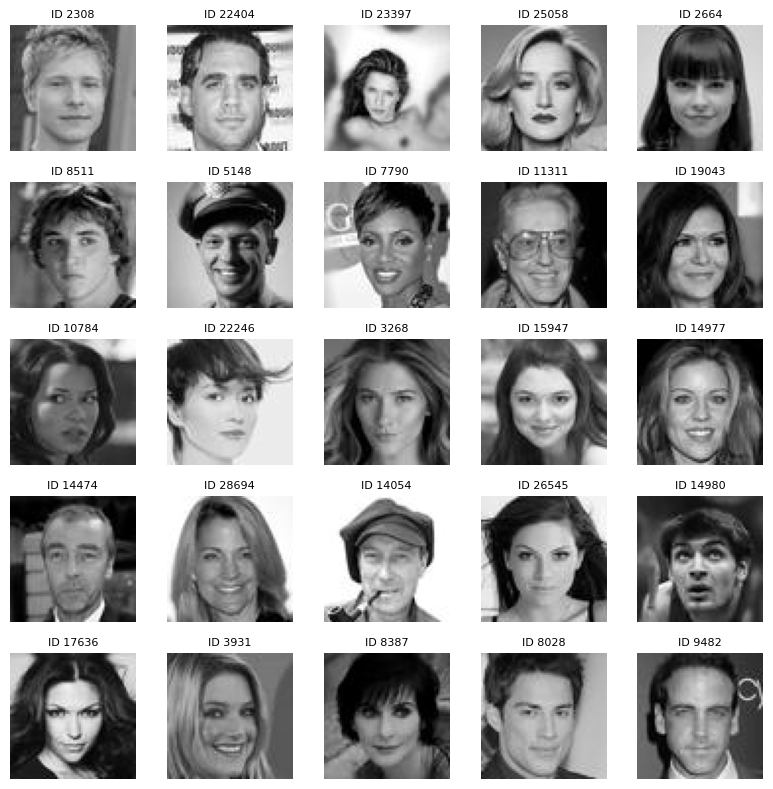

In [ ]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))

np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
# Normalizamos a [0,1] y separamos 27.000 imágenes para train y 3.000 para validación

x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1) 

val_size = int(VAL_FRACTION * len(x_data))

indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


---

## **3. Modelo (encoder, decoder, autoencoder)**

El modelo sigue siendo un AE determinista con un encoder convolucional, un vector latente (ahora de `LATENT_DIM = 256`) y un decoder convolucional con salida `sigmoid` en `[0, 1]`. Como en el baseline, no contiene ningún otro modelo generativo. La diferencia es que **el latente sale directamente de una `Dense` lineal con L2, sin `BatchNormalization` posterior**.

In [ ]:
# Bloque convolucional común y encoder: por resolución, una conv 4x4 stride 2 (reduce) y una conv 3x3 
# (mezcla la información) por cada bloque de filtros. 
def conv_block(x, filters, kernel_size=3, strides=1):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.LeakyReLU(negative_slope=0.2)(x)


encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="encoder_input")
x = encoder_inputs
for filters in (64, 128, 256, 512):
    x = conv_block(x, filters, kernel_size=4, strides=2)
    x = conv_block(x, filters)

x = layers.Flatten()(x)

z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector"
)(x)

encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

2026-10-23 20:26:15.515467: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-10-23 20:26:15.515609: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-10-23 20:26:15.515624: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-10-23 20:26:15.515845: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-23 20:26:15.515854: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 512)      │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 7,992,064 (30.49 MB)

 Trainable params: 7,988,224 (30.47 MB)

 Non-trainable params: 3,840 (15.00 KB)

In [11]:
# Decoder: Dense a 4x4x512 y cuatro bloques de upsampling bilineal + dos convoluciones
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")

x = layers.Dense(4 * 4 * 512, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 512))(x)

# Cada bloque duplica la resolución: 4 -> 8 -> 16 -> 32 -> 64
for filters in (512, 256, 128, 64):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = conv_block(x, filters)
    x = conv_block(x, filters)

decoder_outputs = layers.Conv2D(
    1,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="decoder_output"
)(x)

decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()

Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8192)           │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 256)    │     1,179,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 9,179,201 (35.02 MB)

 Trainable params: 9,158,977 (34.94 MB)

 Non-trainable params: 20,224 (79.00 KB)

In [ ]:
encoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="autoencoder_input")
autoencoder = keras.Model(
    encoder_input,
    decoder_ae(encoder_ae(encoder_input)),
    name="autoencoder"
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 256)            │     7,992,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 1)      │     9,179,201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,171,265 (65.50 MB)

 Trainable params: 17,147,201 (65.41 MB)

 Non-trainable params: 24,064 (94.00 KB)

#### **Hipótesis de diseño**

- **Dos convoluciones por resolución**: En cada resolución una convolución `4x4` con `stride=2` reduce y otra `3x3` refina. Esto se hace con el fin de que la red refine o una los rasgos tras cada cambio de resolución, tanto al codificar como al decodificar.
- **512 filtros**: Hemos duplicado la capacidad por capa respecto al baseline para que el encoder conserve más información antes de comprimirla. El downside de esto es que más parámetros no garantizan mejores muestras y el modelo es mucho más pesado de entrenar.
- **Latente de 256.** El cuello de botella pasa de `4096` píxeles a `256` números, una compresión de `16x` (frente a `32x` en el baseline). Un latente mayor permite recuperar más detalle y reconstrucciones más nítidas. 

#### **Consecuencia de quitar la BN del latente**

`z` deja de tener una escala concreta y el latente queda **sin restricción de escala**: las medias y desviaciones de `z` serán las que el entrenamiento determine. Por eso podremos ver más adelante que `N(0, I)` deja de ser un buen muestreo y hay que **ajustarlo a `z_train`**.

---

## **4. Pérdida y entrenamiento (+ guardado y carga de modelos)**

Mismo que en el baseline.

In [ ]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    ssim = 1.0 - tf.reduce_mean(
        tf.image.ssim(y_true, y_pred, max_val=1.0)
    )
    return 0.5 * l1 + 0.5 * ssim

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=ssim_l1_loss
)


def make_dataset(x_array, training=True):
    dataset = tf.data.Dataset.from_tensor_slices((x_array, x_array))
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(x_array), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            lambda image, target: (
                tf.image.random_flip_left_right(image),
                target
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        # Entrada y objetivo son la misma imagen volteada
        dataset = dataset.map(
            lambda image, _: (image, image),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(x_train, training=True)
val_ds = make_dataset(x_val, training=False)

callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

In [ ]:
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        train_ds,
        epochs=EPOCHS,
        validation_data=val_ds,
        callbacks=callbacks
    )
else:
    print("TRAIN_MODEL = False: no se entrena; los modelos se cargan en la celda de carga.")

Epoch 1/60


2026-10-23 20:26:17.634945: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


211/211 ━━━━━━━━━━━━━━━━━━━━ 191s 883ms/step - loss: 0.3705 - val_loss: 0.4203 - learning_rate: 0.0010
Epoch 2/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 204s 964ms/step - loss: 0.2457 - val_loss: 0.2735 - learning_rate: 0.0010
Epoch 3/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 204s 965ms/step - loss: 0.2088 - val_loss: 0.2101 - learning_rate: 0.0010
Epoch 4/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 205s 972ms/step - loss: 0.1885 - val_loss: 0.2253 - learning_rate: 0.0010
Epoch 5/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 207s 980ms/step - loss: 0.1738 - val_loss: 0.2441 - learning_rate: 0.0010
Epoch 6/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 211s 999ms/step - loss: 0.1653 - val_loss: 0.2419 - learning_rate: 0.0010
Epoch 7/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 212s 1s/step - loss: 0.1578 - val_loss: 0.1832 - learning_rate: 0.0010
Epoch 8/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 225s 1s/step - loss: 0.1520 - val_loss: 0.1882 - learning_rate: 0.0010
Epoch 9/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 221s 1s/step - loss: 0.1461 - val_loss: 0.1807 - learning_rate: 0

In [ ]:
if TRAIN_MODEL:
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    print(f"Modelos guardados en {CHECKPOINT_DIR}/")

Modelos guardados en checkpoints/


In [ ]:
if TRAIN_MODEL:
    history_dict = {
        key: [float(v) for v in values]
        for key, values in history_ae.history.items()
    }
    with open(HISTORY_PATH, "w") as f:
        json.dump(history_dict, f, indent=2)
    print(f"Historial guardado en {HISTORY_PATH}")

Historial guardado en checkpoints/ae_complex2_history.json


In [ ]:
if not TRAIN_MODEL:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [p for p in required if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError(
            f"TRAIN_MODEL=False pero faltan ficheros guardados: {missing}."
            "Ejecuta una vez con TRAIN_MODEL=True para entrenar y guardarlos."
        )

    # compile=False: la pérdida no hace falta para predecir
    autoencoder = keras.models.load_model(AE_PATH, compile=False)
    encoder_ae = keras.models.load_model(ENCODER_PATH, compile=False)
    decoder_ae = keras.models.load_model(DECODER_PATH, compile=False)
    with open(HISTORY_PATH) as f:
        history_ae = SimpleNamespace(history=json.load(f))

    print("Modelos cargados desde disco, no se ha entrenado en esta ejecución.")
    print(f"  autoencoder: {AE_PATH}")
    print(f"  encoder:     {ENCODER_PATH}")
    print(f"  decoder:     {DECODER_PATH}")
    print(f"  historial:   {HISTORY_PATH} ({len(history_ae.history['loss'])} épocas)")
else:
    VERIFY_SAVE = True
    if VERIFY_SAVE:
        z_check = np.random.default_rng(SAMPLE_SEED).normal(
            size=(8, LATENT_DIM)
        ).astype(np.float32)
        decoder_reloaded = keras.models.load_model(DECODER_PATH, compile=False)
        same = np.allclose(
            decoder_ae.predict(z_check, verbose=0),
            decoder_reloaded.predict(z_check, verbose=0),
            atol=1e-6
        )
        assert same, "El decoder recargado no coincide con el decoder en memoria."
        print("Verificación OK: decoder recargado == decoder en memoria (8 muestras fijas).")

# Evita cargar por error checkpoints antiguos con BN en el latente
assert not any(l.name == "latent_standardization" for l in encoder_ae.layers), \
    "Este encoder tiene BN en el latente: son checkpoints antiguos. Reentrena con TRAIN_MODEL=True."
assert encoder_ae.output_shape[-1] == LATENT_DIM, \
    "La dimensión del latente del encoder no coincide con LATENT_DIM. Reentrena con TRAIN_MODEL=True."

Verificación OK: decoder recargado == decoder en memoria (8 muestras fijas).


---

## **5. Resultados del entrenamiento y reconstrucciones**

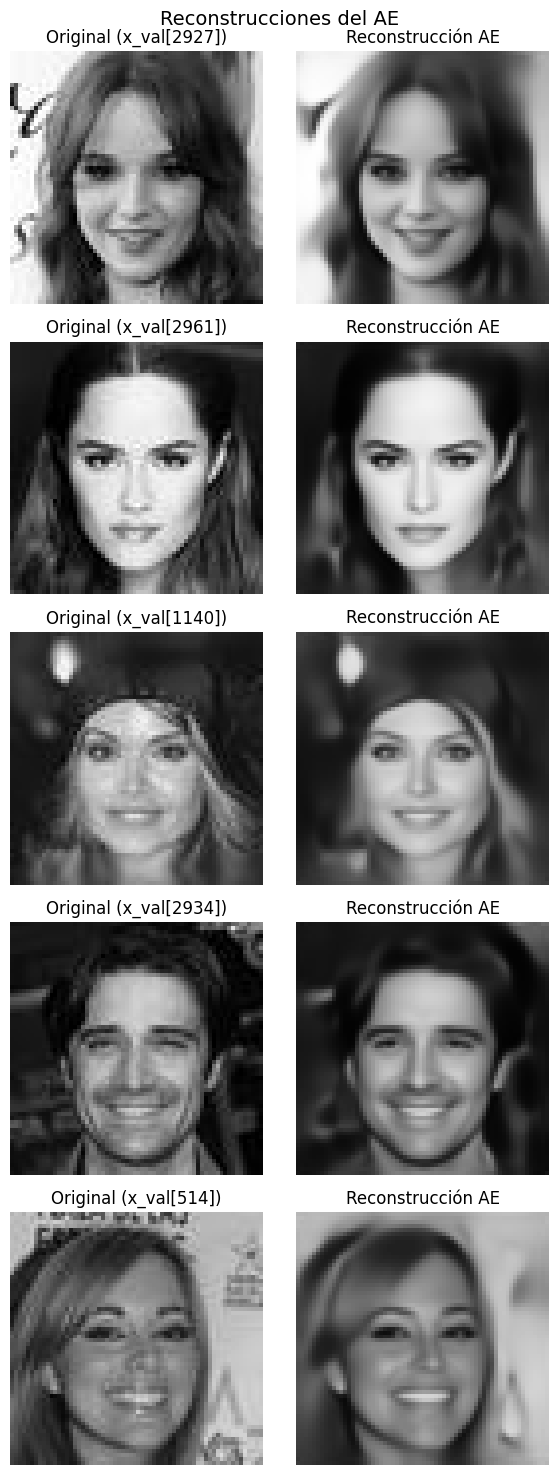

In [ ]:
COMPARISON_SEED = SEED
comparison_rng = np.random.default_rng(COMPARISON_SEED)

comparison_indices = comparison_rng.choice(len(x_val), size=5, replace=False)
x_val_samples = x_val[comparison_indices]

ae_reconstructions = autoencoder.predict(x_val_samples, verbose=0)

fig, axes = plt.subplots(5, 2, figsize=(6, 15))
fig.suptitle("Reconstrucciones del AE", fontsize=14)

for row, (original, reconstruction, sample_index) in enumerate(
    zip(x_val_samples, ae_reconstructions, comparison_indices)
):
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (x_val[{sample_index}])")
    axes[row, 1].imshow(reconstruction[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Reconstrucción AE")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [19]:
# Resumen de la mejor epoch según la pérdida de validación
metrics_history = history_ae.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 59
Train loss:      0.0846
Validation loss: 0.0877


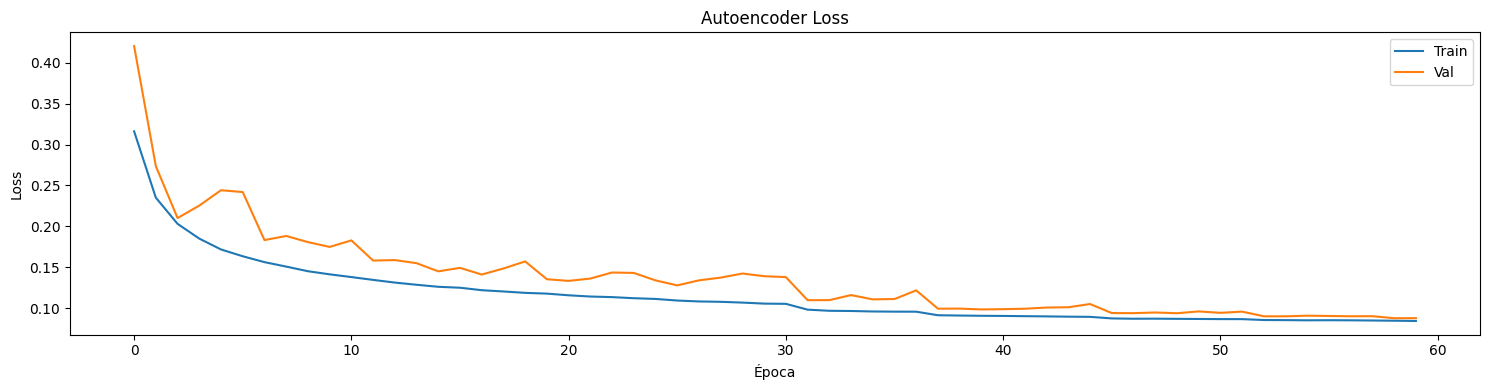

In [20]:
# Curvas para detectar convergencia y posible overfitting
fig, axes = plt.subplots(1, figsize=(15, 4))

axes.plot(history_ae.history["loss"], label="Train")
axes.plot(history_ae.history["val_loss"], label="Val")
axes.set_title("Autoencoder Loss")
axes.set_xlabel("Época")
axes.set_ylabel("Loss")
axes.legend()

plt.tight_layout()
plt.show()

---

## **6. Protocolo FID y Techo del Decoder**

**Adaptación de Datos e Inferencia**
El cálculo del FID requiere adaptar las imágenes a las especificaciones del modelo de **Inception-v3**, la cual impone restricciones implementadas en `prepare_images_for_fid`:
1. **Rango:** Conversión de intensidades entre $[0, 1]$ a $[0, 255]$.
2. **Canales:** Duplicación del canal único en escala de grises a 3 canales RGB.
3. **Formato de tensores:** Transposición del orden de dimensiones de Keras `(B, H, W, C)` al estándar de PyTorch `(B, C, H, W)`.

**Optimización del Cómputo**
El cálculo de FID requiere proyectar tanto las imágenes de referencia como las sintéticas a través de Inception-v3 en cada evaluación. Dado el alto volumen de métodos que vamos a analizar en este notebook, procesar repetidamente `x_val` es muy costoso computacionamente y hemos desarrollado gracias a **`Gemini`** un sistema que reduce a la mitad el tiempo de inferencia. La clase `FidEvaluator` implementa un sistema de almacenamiento en caché mediante el parámetro `reset_real_features=False` de Torchmetrics:

* **Extracción persistente:** Proyecta la referencia real `x_val[:n]` una vez por cada tamaño $N$ y retiene sus estadísticas ($\mu_r, \Sigma_r$) en memoria.
* **Reinicio:** En cada llamada de evaluación, `fid.reset()` elimina solo las estadísticas de las imágenes sintéticas por lo que solo necesitamos la inferencia sobre las nuevas muestras generadas.
* **Consistencia:** Se ejecuta un test comparando la salida de `FidEvaluator` frente a la implementación sin estado `calculate_fid`. La caché solo se activa (`USE_FID_CACHE=True`) si la diferencia es inferior a $0.1$ para estar seguros de que funciona.

In [ ]:
# Funciones de FID del baseline
FID_SEED = SEED

device = "cpu"

def prepare_images_for_fid(images):
    images = np.asarray(images)

    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)

    if images.ndim == 3:
        images = images[..., np.newaxis]

    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(device)
    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(device), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(device), real=False)
        return fid.compute().item()


def decode(z):
    return decoder_ae.predict(np.asarray(z, dtype=np.float32), batch_size=FID_BATCH_SIZE, verbose=0)

In [ ]:
class FidEvaluator:
    def __init__(self, real_images, batch_size=FID_BATCH_SIZE):
        self.real_images = real_images
        self.batch_size = batch_size
        self.metrics = {}

    def _metric_for(self, n):
        if n not in self.metrics:
            fid = FrechetInceptionDistance(
                feature=2048, normalize=False, reset_real_features=False
            ).to(device)
            real = prepare_images_for_fid(self.real_images[:n])
            with torch.inference_mode():
                for start in range(0, len(real), self.batch_size):
                    fid.update(real[start:start + self.batch_size].to(device), real=True)
            self.metrics[n] = fid
        return self.metrics[n]

    def compute(self, generated_images):
        n = len(generated_images)
        fid = self._metric_for(n)
        fid.reset()  # mantenemos las características reales y eliminamos las generadas
        generated = prepare_images_for_fid(generated_images)
        with torch.inference_mode():
            for start in range(0, len(generated), self.batch_size):
                fid.update(generated[start:start + self.batch_size].to(device), real=False)
            return fid.compute().item()


fid_evaluator = FidEvaluator(x_val)

# Validación frente a calculate_fid con un conjunto generado cualquiera (y repitiendo para comprobar el reset)
check_z = np.random.default_rng(SEED).normal(size=(FID_NUM_IMAGES_SUBMISSION, LATENT_DIM))
check_imgs = decode(check_z)
fid_plain = calculate_fid(check_imgs, x_val[:len(check_imgs)])
fid_cached_1 = fid_evaluator.compute(check_imgs)
fid_cached_2 = fid_evaluator.compute(check_imgs)
USE_FID_CACHE = abs(fid_cached_1 - fid_plain) < 0.1 and abs(fid_cached_2 - fid_plain) < 0.1
print(f"calculate_fid: {fid_plain:.4f} | caché: {fid_cached_1:.4f} y {fid_cached_2:.4f} | usar caché: {USE_FID_CACHE}")


def fid_images(generated_images):
    n = len(generated_images)
    assert n <= len(x_val), "No hay suficientes imágenes de validación como referencia."
    if USE_FID_CACHE:
        return fid_evaluator.compute(generated_images)
    return calculate_fid(generated_images, x_val[:n], batch_size=FID_BATCH_SIZE)


def fid_from_z(z):
    return fid_images(decode(z))

calculate_fid: 232.0753 | caché: 232.0753 y 232.0753 | usar caché: True


In [23]:
# FID de las reconstrucciones de validación con N=512 y N=200 (techo del decoder)
fid_recon = {}
for n_images in (FID_NUM_IMAGES_REF, FID_NUM_IMAGES_SUBMISSION):
    n = min(len(x_val), n_images)
    recon = autoencoder.predict(x_val[:n], batch_size=FID_BATCH_SIZE, verbose=0)
    fid_recon[n_images] = fid_images(recon)
    print(f"N={n}: FID reconstrucciones = {fid_recon[n_images]:.4f}")

fid_recon_512 = fid_recon[FID_NUM_IMAGES_REF]
fid_recon_200 = fid_recon[FID_NUM_IMAGES_SUBMISSION]

N=512: FID reconstrucciones = 70.1426
N=200: FID reconstrucciones = 84.0288


---

## **7. Espacio latente actual**

z_train: (27000, 256)
Media por dimensión  -> min -7.267 | mediana -0.054 | max +6.073
Desv. por dimensión  -> min 0.591 | mediana 0.705 | max 3.327
Norma media de z_train: 25.858 (esperada para N(0, I): ~sqrt(256) = 16.000)
Correlación |r| fuera de la diagonal -> media 0.0374 | máx 0.3524
Dimensión efectiva (95% de la varianza): 211 de 256


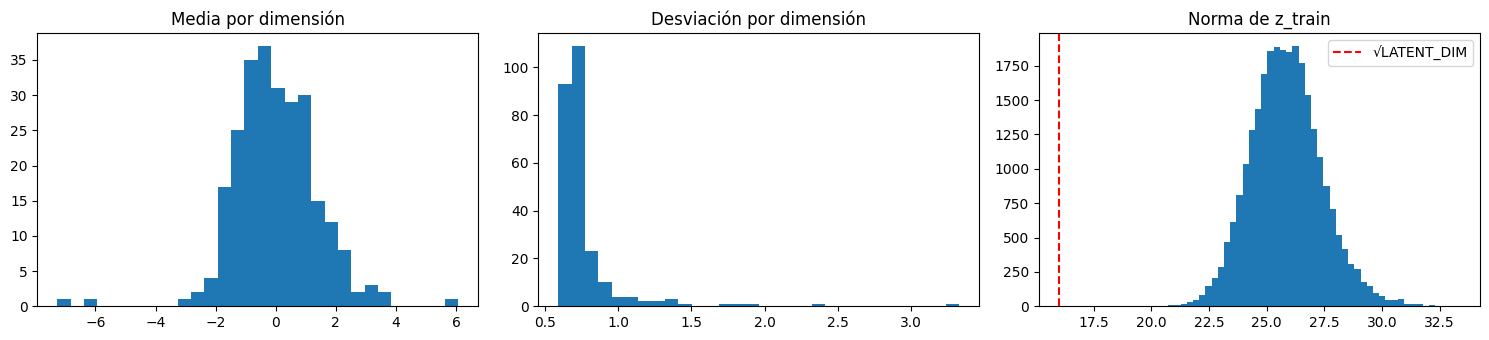

In [ ]:
# Estadísticas de z_train 
z_train = encoder_ae.predict(x_train, batch_size=BATCH_SIZE, verbose=0)

z_mean = z_train.mean(axis=0)
z_std = z_train.std(axis=0)
print(f"z_train: {z_train.shape}")
print(f"Media por dimensión  -> min {z_mean.min():+.3f} | mediana {np.median(z_mean):+.3f} | max {z_mean.max():+.3f}")
print(f"Desv. por dimensión  -> min {z_std.min():.3f} | mediana {np.median(z_std):.3f} | max {z_std.max():.3f}")

norms = np.linalg.norm(z_train, axis=1)
print(f"Norma media de z_train: {norms.mean():.3f} (esperada para N(0, I): ~sqrt({LATENT_DIM}) = {np.sqrt(LATENT_DIM):.3f})")

corr = np.corrcoef(z_train, rowvar=False)
off_diag = np.abs(corr[~np.eye(LATENT_DIM, dtype=bool)])
print(f"Correlación |r| fuera de la diagonal -> media {off_diag.mean():.4f} | máx {off_diag.max():.4f}")

eigvals = np.clip(np.linalg.eigvalsh(np.cov(z_train.T))[::-1], 0.0, None)
explained = np.cumsum(eigvals) / eigvals.sum()
n_eff_95 = int(np.searchsorted(explained, 0.95) + 1)
print(f"Dimensión efectiva (95% de la varianza): {n_eff_95} de {LATENT_DIM}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(z_mean, bins=30)
axes[0].set_title("Media por dimensión")
axes[1].hist(z_std, bins=30)
axes[1].set_title("Desviación por dimensión")
axes[2].hist(norms, bins=50)
axes[2].axvline(np.sqrt(LATENT_DIM), color="r", linestyle="--", label="√LATENT_DIM")
axes[2].set_title("Norma de z_train")
axes[2].legend()
plt.tight_layout()
plt.show()

Como podemos observar, el espacio latente de este AE no tiene nada que ver con el del baseline, como era de esperar. Por ello, ahora sí que el muestreo adaptado es necesario y el muestreo mediante `N(0, I)` tendrá unos resultados muy malos.

---

## **8. Métodos de muestreo y batería de evaluación FID**

El objetivo es evaluar diferentes estrategias para aproximar la densidad del espacio latente $p(z)$ utilizando las representaciones de entrenamiento:

$$\mathcal{Z}_{\text{train}} = \{z_i = \text{Encoder}(x_i) \mid x_i \in \mathcal{D}_{\text{train}}\}$$

> Ningún método de muestreo tiene acceso a $\mathcal{D}_{\text{val}}$. Los vectores $z_{\text{gen}}$ creados por cada técnica se decodifican mediante $\hat{x} = \text{Decoder}(z_{\text{gen}})$ y se evalúan mediante **FID** utilizando las imágenes reales de $x_{\text{val}}$ como referencia.

#### **1. Normal Estándar: $\mathcal{N}(\mathbf{0}, \mathbf{I})$**
* Asume regularización por normalización por lotes.
* **Limitación:** Al ser un autoencoder estándar sin capa de BN y con una distribución del latente muy distinta, los resultados serán muy malos.

#### **2. Uniforme por Dimensión: $\mathcal{U}(\mu_j \pm \sqrt{3}\sigma_j)$**
* Se calcula la media muestral $\mu_j$ y la desviación $\sigma_j$ por dimensión $j \in \{1, \dots, D\}$ en $\mathcal{Z}_{\text{train}}$. Definimos $[a_j, b_j]$ para que la varianza sea $\sigma_j^2$:
  $$\text{Var}(U) = \frac{(b_j - a_j)^2}{12} = \sigma_j^2 \implies (b_j - a_j) = 2\sqrt{3}\sigma_j$$
  $$z_j \sim \mathcal{U}\left(\mu_j - \sqrt{3}\sigma_j, \; \mu_j + \sqrt{3}\sigma_j\right)$$
* **Fundamento:** Tiene la misma media y dispersión por canal que los datos, pero con densidad plana. 

#### **3. Gaussiana Diagonal: $\mathcal{N}(\boldsymbol{\mu}, \text{diag}(\boldsymbol{\sigma}^2))$**
* Ajustamos un modelo de densidad normal independiente en cada coordenada en lugar de una uniforme:
  $$z_j \sim \mathcal{N}(\mu_j, \sigma_j^2)$$
* **Limitación:** Estamos asumiendo independencia total entre dimensiones, forzando una matriz de covarianza diagonal ($\Sigma_{ij} = 0 \ \forall \ i \neq j$), algo que probablemente sea falso al ser una simplificación máxima de la realidad. 

#### **4. Gaussiana Multivariante: $\mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$**
* Estima el vector de medias $\boldsymbol{\mu} \in \mathbb{R}^D$ y la matriz de covarianza completa (evitamos la simplificación anterior) $\boldsymbol{\Sigma} \in \mathbb{R}^{D \times D}$:
  $$\boldsymbol{\Sigma} = \frac{1}{M-1}\sum_{i=1}^M (z_i - \boldsymbol{\mu})(z_i - \boldsymbol{\mu})^\top$$
  $$z \sim \mathcal{N}(\boldsymbol{\mu}, \boldsymbol{\Sigma})$$

* **Limitación:** estamos asumiendo unimodalidad: si los datos tienen clases disjuntas, una única gaussiana tenderá a muestrear la media.

#### **5. Gaussian Mixture Models (GMM)**

* Es la extensión de la gaussiana multivariante, usando una suma ponderada de $K$ densidades gaussianas con sus respectivas covarianzas.

* Se selecciona un componente k (una de las categorías), y se extrae el vector a partir de la gaussiana asignada: 

Usamos varios númerosde componentes de prueba:

* **`GMM 2`:** Primer grado de multimodalidad.
* **`GMM 10`:** Se asume que hay varios clusters de datos (por ejemplo varios tipos de caras o expresiones).
* **`GMM 30` y `GMM 50`:** Probamos con mayor capacidad de ajuste. A medida que $K$ se aproxima al tamaño del dataset, los componentes pueden sobreajustar y muestrear puntos muy similares a instancias de entrenamiento.

#### **6. KNN ($K=10$)**

* **Mecanismo:** 
  1. Se selecciona un punto $z_i \in \mathcal{Z}_{\text{train}}$ al azar.
  2. Se identifican sus $K$ vecinos más cercanos mediante distancia euclídea, incluyendo el propio punto.
  3. Se genera un vector de ponderaciones con una distribución de Dirichlet: creamos un vector de $K$ pesos positivos que será la ponderación de cada vecino, y que suman 1.
  4. Se crea el nuevo vector como una combinación lineal.

* **Nitidez:** Al restringir el muestreo a los vecinos, se evita el problema de generación de puntos fuera de la distribución latente. 
* **Ponderación:** Intuitivamente, podemos pensar en porque no hacemos directamente un promedio de los vecinos: si todos los vecinos son muy similares, el promedio será muy parecido a ellos y la imagen generada será muy nítida. Si los vecinos son muy distintos, el promedio será un punto intermedio que no se parece a ninguno de ellos y la imagen generada será borrosa. 
Un promedio es una distribución de Dirichlet con los mismos pesos para todos los vecinos, mientras que si lo aleatorizamos, podemos ponderar más a unos vecinos que a otros y evitar este problema. Además, así podemos generar infinitos puntos distintos dentro del espacio que encierran esos 10 vecinos.

In [ ]:
z_fit = z_train.astype(np.float64)
mu = z_fit.mean(axis=0)
sigma = z_fit.std(axis=0)
cov = np.cov(z_fit, rowvar=False)

gmms, gmm_chol, gmm_reg_used = {}, {}, {}
for k in GMM_COMPONENTS:
    path = GMM_PATH.format(k=k)
    if TRAIN_MODEL or not os.path.exists(path):
        for attempt in range(4):
            reg = GMM_REG_COVAR * 10 ** attempt
            t0 = time.time()
            gmm = GaussianMixture(
                k, covariance_type="full", reg_covar=reg, random_state=SEED
            ).fit(z_fit)
            try:
                chol = [np.linalg.cholesky(c) for c in gmm.covariances_]
            except np.linalg.LinAlgError:
                print(f"GMM {k}: falla con reg_covar={reg:g}; se sube reg_covar.")
                continue
            if not gmm.converged_:
                print(f"GMM {k}: no converge con reg_covar={reg:g}; se sube reg_covar.")
                continue
            break
        else:
            raise RuntimeError(f"GMM {k}: sin convergencia tras subir reg_covar hasta {reg:g}.")
        gmm_reg_used[k] = reg
        os.makedirs(CHECKPOINT_DIR, exist_ok=True)
        joblib.dump({"gmm": gmm, "reg_covar": reg}, path)
        origin = f"ajustado en {time.time() - t0:.1f}s"
    else:
        saved = joblib.load(path)
        gmm, gmm_reg_used[k] = saved["gmm"], saved["reg_covar"]
        assert gmm.means_.shape[1] == LATENT_DIM, f"GMM {k} guardado con otra dimensión de latente."
        chol = [np.linalg.cholesky(c) for c in gmm.covariances_]
        origin = "cargado de disco"
    gmms[k], gmm_chol[k] = gmm, chol
    print(f"GMM {k}: {origin} | converged_ = {gmm.converged_} | reg_covar = {gmm_reg_used[k]:g}")

t0 = time.time()
knn = NearestNeighbors(n_neighbors=KNN_K).fit(z_fit)
knn_idx = knn.kneighbors(z_fit, return_distance=False)   # (len(z_train), KNN_K)
print(f"kNN: índices de vecinos {knn_idx.shape} calculados en {time.time() - t0:.1f}s")

GMM 2: ajustado en 4.2s | converged_ = True | reg_covar = 0.0001
GMM 10: ajustado en 62.9s | converged_ = True | reg_covar = 0.0001
GMM 30: ajustado en 40.7s | converged_ = True | reg_covar = 0.0001
GMM 50: ajustado en 33.6s | converged_ = True | reg_covar = 0.0001
kNN: índices de vecinos (27000, 10) calculados en 1.3s


In [ ]:
def sample_standard_normal(n, rng):
    return rng.normal(size=(n, LATENT_DIM)).astype(np.float32)


def sample_uniform(n, rng):
    half_width = np.sqrt(3.0) * sigma
    return rng.uniform(mu - half_width, mu + half_width, size=(n, LATENT_DIM)).astype(np.float32)


def sample_diagonal_gaussian(n, rng):
    return rng.normal(mu, sigma, size=(n, LATENT_DIM)).astype(np.float32)


def sample_multivariate_gaussian(n, rng):
    return rng.multivariate_normal(mu, cov, size=n).astype(np.float32)


def make_gmm_sampler(k):
    gmm, chol = gmms[k], gmm_chol[k]
    weights = gmm.weights_ / gmm.weights_.sum()

    def sampler(n, rng):
        # Una componente por muestra y z = media_k + L_k @ eps con L_k la Cholesky de la covarianza
        comp = rng.choice(gmm.n_components, size=n, p=weights)
        z = np.empty((n, LATENT_DIM))
        for c in range(gmm.n_components):
            idx = np.where(comp == c)[0]
            if len(idx):
                eps = rng.normal(size=(len(idx), LATENT_DIM))
                z[idx] = gmm.means_[c] + eps @ chol[c].T
        return z.astype(np.float32)

    return sampler


def sample_knn_barycentric(n, rng):
    anchor = rng.integers(len(z_train), size=n)
    w = rng.dirichlet(np.ones(KNN_K), size=n)
    return np.einsum("nk,nkd->nd", w, z_fit[knn_idx[anchor]]).astype(np.float32)


SAMPLERS = {
    "N(0, I)": sample_standard_normal,
    "Uniforme": sample_uniform,
    "Gaussiana diagonal": sample_diagonal_gaussian,
    "Gaussiana multivariante": sample_multivariate_gaussian,
}
for k in GMM_COMPONENTS:
    SAMPLERS[f"GMM {k}"] = make_gmm_sampler(k)
SAMPLERS[f"kNN baricéntrico (K={KNN_K})"] = sample_knn_barycentric

print(f"{len(SAMPLERS)} métodos: {list(SAMPLERS)}")

9 métodos: ['N(0, I)', 'Uniforme', 'Gaussiana diagonal', 'Gaussiana multivariante', 'GMM 2', 'GMM 10', 'GMM 30', 'GMM 50', 'kNN baricéntrico (K=10)']


In [ ]:
# Batería: FID con N=512 (una muestra) y N=200 (varias muestras) por método
rows, fid_200_runs = [], {}
for name, sampler in SAMPLERS.items():
    t0 = time.time()
    fid_512_method = fid_from_z(sampler(FID_NUM_IMAGES_REF, np.random.default_rng(SEED)))
    runs = [
        fid_from_z(sampler(FID_NUM_IMAGES_SUBMISSION, np.random.default_rng(SEED + r)))
        for r in range(N_FID_REPEATS)
    ]
    fid_200_runs[name] = runs
    rows.append({
        "method": name,
        "fid_200_mean": float(np.mean(runs)),
        "fid_200_std": float(np.std(runs, ddof=1)),
        "fid_512": float(fid_512_method),
        "gap_vs_recon_200": float(np.mean(runs) - fid_recon_200),
    })
    print(f"{name:32s} FID200 = {np.mean(runs):7.2f} ± {np.std(runs, ddof=1):5.2f} | FID512 = {fid_512_method:7.2f} ({time.time() - t0:.0f}s)")

df_samplers = pd.DataFrame(rows).sort_values(RANKING_METRIC).reset_index(drop=True)
print(f"\nFID reconstrucciones: N=200 -> {fid_recon_200:.2f} | N=512 -> {fid_recon_512:.2f}")
print(df_samplers.round(2).to_string())

N(0, I)                          FID200 =  231.18 ±  3.42 | FID512 =  215.95 (154s)
Uniforme                         FID200 =  107.20 ±  1.85 | FID512 =   92.76 (152s)
Gaussiana diagonal               FID200 =  107.16 ±  1.16 | FID512 =   91.93 (154s)
Gaussiana multivariante          FID200 =  100.30 ±  1.10 | FID512 =   87.18 (161s)
GMM 2                            FID200 =   99.84 ±  1.59 | FID512 =   84.96 (165s)
GMM 10                           FID200 =   95.68 ±  2.07 | FID512 =   81.10 (163s)
GMM 30                           FID200 =   94.01 ±  1.68 | FID512 =   79.35 (162s)
GMM 50                           FID200 =   93.19 ±  1.15 | FID512 =   78.79 (163s)
kNN baricéntrico (K=10)          FID200 =   92.36 ±  0.77 | FID512 =   79.54 (161s)

FID reconstrucciones: N=200 -> 84.03 | N=512 -> 70.14
                    method  fid_200_mean  fid_200_std  fid_512  gap_vs_recon_200
0  kNN baricéntrico (K=10)         92.36         0.77    79.54              8.33
1                   GMM 50 

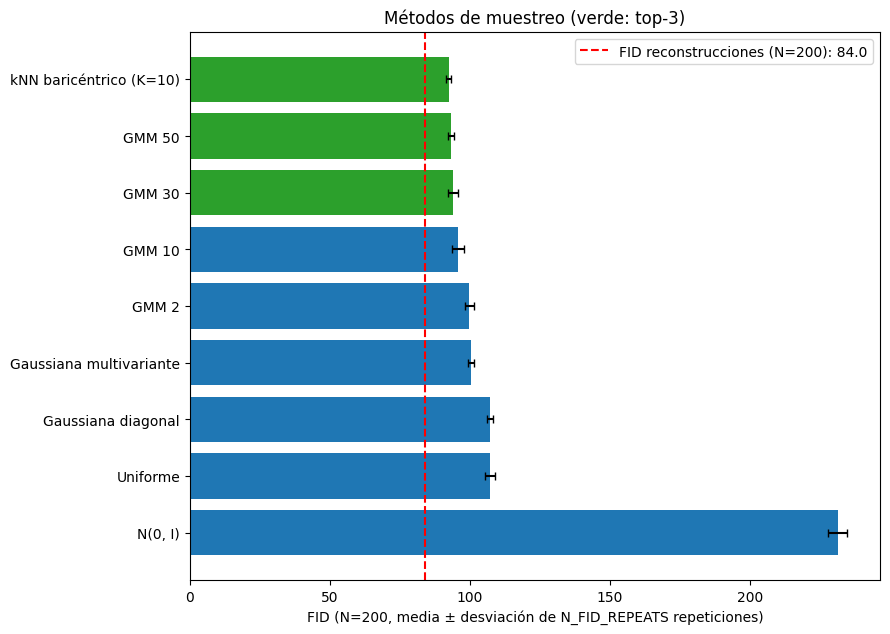

In [ ]:
fig, ax = plt.subplots(figsize=(9, 0.55 * len(df_samplers) + 1.5))
colors = ["tab:green" if i < TOP_K_SUBMIT else "tab:blue" for i in range(len(df_samplers))]
ax.barh(df_samplers["method"], df_samplers["fid_200_mean"], xerr=df_samplers["fid_200_std"],
        color=colors, capsize=3)
ax.axvline(fid_recon_200, color="r", linestyle="--", label=f"FID reconstrucciones (N=200): {fid_recon_200:.1f}")
ax.invert_yaxis()
ax.set_xlabel("FID (N=200, media ± desviación de N_FID_REPEATS repeticiones)")
ax.set_title(f"Métodos de muestreo (verde: top-{TOP_K_SUBMIT})")
ax.legend()
plt.tight_layout()
plt.show()

### **Interpretación**

- Como era de esperar, el muestreo mediante `N(0, I)` ha sido el peor con mucha diferencia.

- La Uniforme y la Diagonal han sido mejores que `N(0, I)` pero peores que la Multivariante, que a su vez ha sido peor que los GMM y el kNN.

- El aumento de componentes del GMM ha mejorado el FID, pero cada vez en menor medida. Esto puede deberse a que los GMM con muchos componentes tienden a sobreajustar y muestrear puntos muy similares a instancias de entrenamiento, lo que empeora el FID.

- El KNN ha sido el mejor método como esperabamos.

La capacidad del decodificador para generar imágenes realistas está muy ligada a la compatibilidad de los vectores latentes de entrada con la distribución de entrenamiento. Para bajarlo a tierra, hagamos una metáfora: digamos que un artista elabora retratos uniendo cubos de `Rubik` de **3x3**: su método asume esa dimensionalidad y granularidad a las que está acostumbrado; sin embargo, si le damos cubos de **5x5** generará resultados mucho peores. Esto no será por un fallo en su destreza, sino por entregarle primitivas completamente distintas a lo que está acostumbrado. En términos formales, el decodificador no tiene un fallo intrínseco de capacidad, sino una limitación inherente por un problema de extrapolación fuera de distribución, ya que las representaciones latentes dadas no respetan la geometría del espacio latente sobre el que ha sido optimizado.

---

## **9. Mejores métodos: imágenes, submissions y métricas**

Se dibujan las caras generadas por el top-5 (junto a imágenes reales de `x_val`) con `SAMPLE_SEED`, distinta de las semillas del FID. Después se genera una submission de `N_SAMPLES = 200` imágenes para cada uno de los **3 mejores métodos**. Se guardan 3 y no 1 porque el FID de Kaggle con 200 imágenes es muy aleatorio, y así se reparte el riesgo. Se vuelve a leer el CSV, se reconstruyen las imágenes y se calcula su FID local (`N = 200`) como comprobación. 

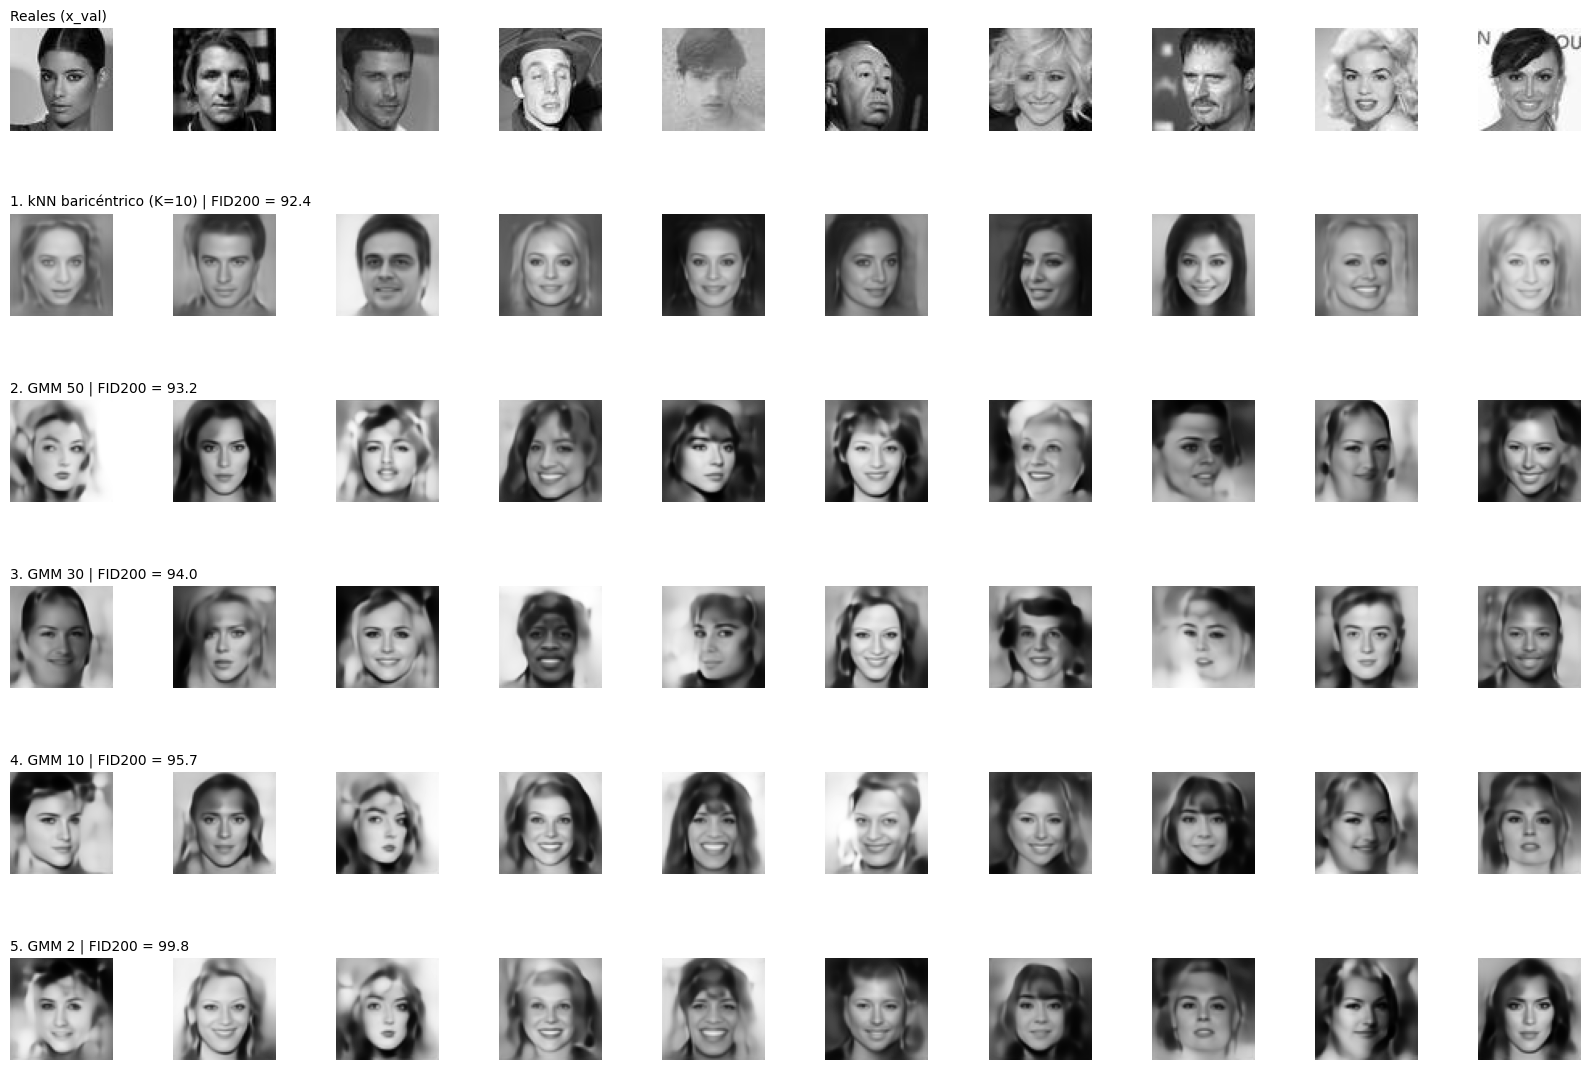

In [ ]:
n_cols = 10
fig, axes = plt.subplots(TOP_K_SHOW + 1, n_cols, figsize=(1.6 * n_cols, 1.9 * (TOP_K_SHOW + 1)))
for c in range(n_cols):
    axes[0, c].imshow(x_val[c, ..., 0], cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Reales (x_val)", loc="left", fontsize=10)

for r, row in enumerate(df_samplers.head(TOP_K_SHOW).itertuples(), start=1):
    imgs = decode(SAMPLERS[row.method](n_cols, np.random.default_rng(SAMPLE_SEED)))
    for c in range(n_cols):
        axes[r, c].imshow(imgs[c, ..., 0], cmap="gray", vmin=0, vmax=1)
    axes[r, 0].set_title(f"{r}. {row.method} | FID200 = {row.fid_200_mean:.1f}", loc="left", fontsize=10)

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Exportación de submissions
def clean_text(name):
    text = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


def save_submission(generated_imgs_uint8, path):
    flat_pixels = generated_imgs_uint8.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)
    df_submission = pd.DataFrame(
        flat_pixels,
        columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
    )
    df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

    assert df_submission.shape == (N_SAMPLES, 1 + IMG_SIZE * IMG_SIZE)
    assert df_submission.isnull().sum().sum() == 0
    assert df_submission.iloc[:, 1:].values.min() >= 0
    assert df_submission.iloc[:, 1:].values.max() <= 255
    assert list(df_submission.columns[:2]) == ["ID", "0"]

    os.makedirs(SUBMISSIONS_DIR, exist_ok=True)
    df_submission.to_csv(path, index=False)
    return df_submission


submission_paths = {}
for rank, row in enumerate(df_samplers.head(TOP_K_SUBMIT).itertuples(), start=1):
    z_sub = SAMPLERS[row.method](N_SAMPLES, np.random.default_rng(SAMPLE_SEED))
    generated_float = decode(z_sub)
    assert generated_float.shape == (N_SAMPLES, IMG_SIZE, IMG_SIZE, 1)
    assert np.isfinite(generated_float).all()
    assert generated_float.min() >= 0.0 and generated_float.max() <= 1.0
    generated_imgs = np.squeeze(np.clip(np.round(generated_float * 255.0), 0, 255).astype(np.uint8), axis=-1)

    path = f"{SUBMISSIONS_DIR}/submission_{NOTEBOOK_NAME}_top{rank}_{clean_text(row.method)}.csv"
    df_sub = save_submission(generated_imgs, path)
    submission_paths[row.method] = path

    df_back = pd.read_csv(path)
    imgs_back = df_back.iloc[:, 1:].values.astype(np.uint8).reshape(N_SAMPLES, IMG_SIZE, IMG_SIZE)
    assert np.array_equal(imgs_back, generated_imgs), "El CSV no coincide con las imágenes en memoria."
    fid_memory = fid_images(generated_imgs)
    fid_csv = fid_images(imgs_back)
    assert abs(fid_memory - fid_csv) < 1e-3
    print(f"top{rank} {row.method}: '{path}' | forma {df_sub.shape} | FID local (N=200) memoria={fid_memory:.4f} CSV={fid_csv:.4f}")

top1 kNN baricéntrico (K=10): 'submissions/submission_ae_complex2_top1_knn_baricentrico_k_10.csv' | forma (200, 4098) | FID local (N=200) memoria=92.7883 CSV=92.7883
top2 GMM 50: 'submissions/submission_ae_complex2_top2_gmm_50.csv' | forma (200, 4098) | FID local (N=200) memoria=94.7911 CSV=94.7911
top3 GMM 30: 'submissions/submission_ae_complex2_top3_gmm_30.csv' | forma (200, 4098) | FID local (N=200) memoria=94.2744 CSV=94.2744


In [ ]:
# Métricas
os.makedirs(RESULTS_DIR, exist_ok=True)
best = df_samplers.iloc[0]

sampling_results = {}
for row in df_samplers.itertuples():
    entry = {
        "fid_200_mean": float(row.fid_200_mean),
        "fid_200_std": float(row.fid_200_std),
        "fid_512": float(row.fid_512),
    }
    if "fid_full" in df_samplers.columns and not pd.isna(row.fid_full):
        entry["fid_full"] = float(row.fid_full)
    sampling_results[row.method] = entry

metrics = {
    "fid_200": float(best["fid_200_mean"]),
    "fid_512": float(best["fid_512"]),
    "best_epoch": int(best_epoch + 1),
    "train_loss": float(metrics_history["loss"][best_epoch]),
    "val_loss": float(metrics_history["val_loss"][best_epoch]),
    "latent_dim": int(LATENT_DIM),
    "n_params": int(autoencoder.count_params()),
    "sampling_method": str(best["method"]),
    "fid_recon_200": float(fid_recon_200),
    "fid_recon_512": float(fid_recon_512),
    "top3": [str(m) for m in df_samplers["method"].head(3)],
    "sampling_results": sampling_results,
    "gmm_reg_covar_used": {str(k): float(v) for k, v in gmm_reg_used.items()},
}
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)
print(f"Métricas guardadas en {METRICS_PATH}")
print(json.dumps(metrics, indent=2))

Métricas guardadas en results/ae_complex2_metrics.json
{
  "fid_200": 92.36317596435546,
  "fid_512": 79.54279327392578,
  "best_epoch": 59,
  "train_loss": 0.0845620408654213,
  "val_loss": 0.08765047043561935,
  "latent_dim": 256,
  "n_params": 17171265,
  "sampling_method": "kNN baric\u00e9ntrico (K=10)",
  "fid_recon_200": 84.02879333496094,
  "fid_recon_512": 70.14257049560547,
  "top3": [
    "kNN baric\u00e9ntrico (K=10)",
    "GMM 50",
    "GMM 30"
  ],
  "sampling_results": {
    "kNN baric\u00e9ntrico (K=10)": {
      "fid_200_mean": 92.36317596435546,
      "fid_200_std": 0.7664113474348513,
      "fid_512": 79.54279327392578
    },
    "GMM 50": {
      "fid_200_mean": 93.18665008544922,
      "fid_200_std": 1.1519207180773607,
      "fid_512": 78.7897720336914
    },
    "GMM 30": {
      "fid_200_mean": 94.0060531616211,
      "fid_200_std": 1.6808422125240434,
      "fid_512": 79.34752655029297
    },
    "GMM 10": {
      "fid_200_mean": 95.67884216308593,
      "fid_20

---

## **10. Conclusiones y posibles mejoras**

### **Conclusiones de AE 2**

Las métricas de Kaggle han sido las siguientes:
- KNN: 87.7
- GMM 50: 90.1
- GMM 30: 89.35

### **Posibles mejoras**

Estos dos notebooks solo son una compresión de todos los experimentos que han sido realizados en busca del mejor método de muestreo y autoencoder. El primer notebook no fue ni si quiera la primera itereación de experimentos, puesto que la forma de cálculo del FID, el uso del `BatchNormalization` en el espacio latente y la función de pérdida creada, fueron iteraciones de un primer baseline que no ha sido mostrado por motivos de claridad y concisión. 
Además, este notebook ha sido diseñado para tratar la reproducibilidad y la legibilidad de los experimentos. Todos los presentes fueron tratados individualemente con anterioridad y han sido agrupados para que el lector pueda seguir su lógica y resultados de forma más sencilla. 

Por ello, hay algunos experimentos que no quedan reflejados en estos notebooks que merece la pena mencionar, aunque no hayan sido incluidos:

- En primer lugar, si se ha comprendido el funcionamiento de los autoencoders, podría pensarse que el salto de la arquitectura del AE 1 al **AE 2** es demasiado grande y no hace más que aumentar el número de parámetros y tiempo de entrenamiento teniendo rendimientos marginales. La respuesta es que sí, pero que el salto de arquitectura ha sido necesario para poder estudiar la influencia de la función de pérdida y el muestreo en el espacio latente. 
Además, este salto no se dio de forma arbitraria. Partiendo del **AE 1**, se llegó a la conclusión de que el decoder podría no tener capacidad suficiente para reconstruir imágenes de calidad, por lo que se decidió aumentar su capacidad y profundidad. Tras una prueba con este, los resultados fueron mejores, pero no lo suficiente como para notar un gran salto. Al suceder esto, se hizo lo análogo con el espacio latente, aumentándolo de `128 a 256 dimensiones` y manteniendo el resto del modelo como en el **AE 1**. Los resultados tuvieron el mismo patrón que con el aumento del decoder. 
Sin embargo, el salto real llegó al aumentar a la vez el decoder y el latente, lo que hizo mejoras muy sustanciales. 
En este notebook no solo se hace eso, si no que también se ha aumentado el encoder, lo cual ha tenido rendimientos mejores marginales. También se pensó la posibilidad de incluir **skip connections** pero es algo que no tiene sentido: en lugar de aprender a reconstruir la imagen a partir del vector latente z, el decodificador se apoya en los atajos que le vamos aportando. Cuando se quiera generar una imagen nueva desde un z sintético, no habrá una imagen de entrada y el decoder no podrá reconstruirla porque no tendrá la información necesaria. Por ello, se decidió no incluirlas.

- En segundo lugar, el segundo cuello de botella del entrenamiento es la función de pérdida. En este notebook se ha mantenido la misma que en el baseline al ser muy completa, pero se han realizado experimentos con otras funciones de pérdida que con esta estructura es posible que funcionasen mejor pero no hemos podido comprobar. Esta incluía el cálculo de un gradiente para tratar de que los bordes fuesen más nítidos. También podría desarrollarse una función de pérdida más cercana al FID para usar en lugar de `val_loss` y un `CosineDecay` para el learning rate.

- Por último tenemos el muestreo. En este notebook se han probado los más básicos e intuitivos, pero probablemente se podrían haber mejorado usando otros métodos generativos como una **VGG, U-Net o un GAN**, pero no se ha hecho por falta de tiempo y recursos.

Todas estas mejoras dependen únicamente de la capacidad de cómputo y tiempo que dedicar a la experimentación. Por la trivialidad que ello conlleva, se ha optado por tratar de encontrar arquitecturas con un sentido detrás de la experimentación y no por el mero hecho de aumentar el número de parámetros o pruebas hasta hacer overfitting en los datos de testeo.

Como última reflexión, el FID de 200 es muy ruidoso, así que únicamente por la competición, vamos a correr en `overfitting.ipynb` un experimento de overfitting con el fin de ver si podemos mejorar el FID de Kaggle. Esto no tiene sentido en la vida real, por lo que solo lo haremos con el método que mejor resultado dio (KNN) aunque probablemente otros podrían mejorarlos, aunque es un experimento interesante. 
